# **Week 4 Notebook**

This week, we turn to event-driven quantitative research, looking at how stocks behave differently when a specific event occurs.

# Task 1

We start by learning the basic concepts & making a hypothesis for what we're going to study. There is no coding portion for this task.

# Task 2

Now we prepare our event data by building a clean event table, building new dataset from scratch and making estimation / event windows for each event.

This task should ideally produce the following outputs:

1) A dataframe of events including the ticker involved, date, (redundant) event type, and surprise factor if applicable
2) Load in our past OHLCV dataset
3) (function) align event dates with trading days to produce a dataframe that can be readily used
4) Write a function that for each event defines the estimation window and event window (either as a separate dataframe or a simple subset of the existing dataset

In [90]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import time
from scipy import stats
from pathlib import Path

from src.data_utils import load_ohlcv
from src.data_utils import compute_returns

In [9]:
# Load in our data
# If we need to use later:
portfolio_tickers = [
    "NVDA", "AAPL", "GOOGL", "GOOG", "MSFT", "AMZN", "META", "AVGO", "TSLA", "MU",
    "BRK-B", "LLY", "AMD", "JPM", "WMT", "V", "XOM", "INTC", "JNJ", "MA",
    "ABBV", "ORCL", "DIS", "CSCO", "CVX", "COST", "BAC", "LRCX", "KO", "AMAT",
    "MRK", "CAT", "DELL", "PG", "UNH", "GE", "MS", "PANW", "HD", "NFLX",
    "PM", "GS", "IBM", "ANET", "WFC", "CRWD", "RTX", "VZ", "TXN", "TMUS"
]

benchmark_ticker = "SPY"

ohlcv_df = load_ohlcv("../data/processed/ohlcv.parquet")
benchmark = ohlcv_df[ohlcv_df["ticker"] == benchmark_ticker].copy()

In [15]:
def fetch_earnings_events(tickers, start_date="2020-01-01",
                          end_date="2026-05-01", limit=50):
    """
    Simple function that grabs raw earning events data from Yahoo Finance.

    Input:
        tickers: list of tickers from portfolio (list)
        start_date: usually "2020-01-01" (str)
        end_date: here "2026-05-01" (str)
        limit: sets a limit to how many events we pull. Not too important here

    Output:
        dataframe consisting of event data
    """

    event_dfs = []
    failed_tickers = []

    for symbol in tickers:
        try:
            earnings = yf.Ticker(symbol).get_earnings_dates(limit=limit)

            if earnings is None or earnings.empty:
                failed_tickers.append(symbol)
                continue

            df = earnings.reset_index().copy()

            df = df.rename(columns={
                "Earnings Date": "announcement_datetime",
                "EPS Estimate": "eps_estimate",
                "Reported EPS": "reported_eps",
                "Surprise(%)": "surprise_pct"
            })

            df["ticker"] = symbol
            df["event_type"] = "earnings"

            # Convert timestamps to New York time
            df["announcement_datetime"] = (
                pd.to_datetime(df["announcement_datetime"], utc=True)
                .dt.tz_convert("America/New_York")
            )

            # Filter to requested period
            df = df[
                (df["announcement_datetime"] >= pd.Timestamp(start_date, tz="America/New_York")) &
                (df["announcement_datetime"] < pd.Timestamp(end_date, tz="America/New_York") + pd.Timedelta(days=1))
            ].copy()

            event_dfs.append(df)

        except Exception as e:
            print(f"Error fetching {symbol}: {e}")
            failed_tickers.append(symbol)

    if not event_dfs:
        return pd.DataFrame(), failed_tickers

    events_df = pd.concat(event_dfs, ignore_index=True)

    events_df = events_df[
        ["ticker", "announcement_datetime", "event_type",
         "eps_estimate", "reported_eps", "surprise_pct"]
    ]

    events_df = (
        events_df
        .drop_duplicates(subset=["ticker", "announcement_datetime"])
        .sort_values(["ticker", "announcement_datetime"])
        .reset_index(drop=True)
    )

    return events_df, failed_tickers

events_df, failed_tickers = fetch_earnings_events(portfolio_tickers)

print("Total events:", len(events_df))
print("Unique stocks:", events_df["ticker"].nunique())
print("Failed tickers:", failed_tickers)

display(events_df.head(10))

Total events: 1284
Unique stocks: 50
Failed tickers: []


,ticker,announcement_datetime,event_type,eps_estimate,reported_eps,surprise_pct
0,AAPL,2020-01-28 16:00:00-05:00,earnings,1.13,1.25,9.97
1,AAPL,2020-04-30 17:00:00-04:00,earnings,0.56,0.64,12.93
2,AAPL,2020-07-30 16:00:00-04:00,earnings,0.52,0.65,24.45
3,AAPL,2020-10-29 16:00:00-04:00,earnings,0.70,0.73,4.50
4,AAPL,2021-01-27 16:00:00-05:00,earnings,1.42,1.68,18.67
5,AAPL,2021-04-28 16:00:00-04:00,earnings,0.98,1.40,42.16
6,AAPL,2021-07-27 16:00:00-04:00,earnings,1.01,1.30,28.56
7,AAPL,2021-10-28 16:00:00-04:00,earnings,1.24,1.24,0.17
8,AAPL,2022-01-27 16:00:00-05:00,earnings,1.89,2.10,11.20
9,AAPL,2022-04-28 16:00:00-04:00,earnings,1.43,1.52,6.48


In [22]:
# Check that our data is mostly complete

coverage = (
    events_df.groupby("ticker")
    .agg(
        event_count=("announcement_datetime", "size"),
        first_event=("announcement_datetime", "min"),
        last_event=("announcement_datetime", "max")
    )
    .sort_values("event_count")
)

display(coverage.head()) # Dataset is complete!

,event_count,first_event,last_event
ticker,,,
AMD,25,2020-01-28 16:00:00-05:00,2026-02-03 16:00:00-05:00
AMAT,25,2020-02-12 16:00:00-05:00,2026-02-12 16:00:00-05:00
AVGO,25,2020-03-12 16:00:00-04:00,2026-03-04 16:00:00-05:00
ANET,25,2020-02-13 16:00:00-05:00,2026-02-12 16:00:00-05:00
CSCO,25,2020-02-12 16:00:00-05:00,2026-02-11 16:00:00-05:00


In [19]:
# Now let's clean this data so each event points to the correct trading day.
# We say that any event before 4:00PM EST is the same trading day, and anything after will go into the next trading day.

def align_event_dates(events_df, ohlcv_df, benchmark_ticker="SPY"):
    """
    Aligns events to a trading day based on when the announcement was made. Produces a new column to the dataframe.

    Input:
        events_df: dataframe of events from the previous function
        ohlcv_df: loaded-in OHLCV data from load_ohlcv containing tickers & basic stock information
        benchmark_ticker: usually SPY (str)
    Output:
        appended column to events_df with the aligned date
    """

    events = events_df.copy()
    prices = ohlcv_df.copy()

    # Get trading calendar from SPY
    trading_days = (
        pd.to_datetime(
            prices.loc[
                prices["ticker"] == benchmark_ticker, "date"
            ]
        )
        .dt.normalize()
        .drop_duplicates()
        .sort_values()
        .to_numpy(dtype="datetime64[ns]")
    )

    # Ensure announcement timestamps are in New York time
    events["announcement_datetime"] = pd.to_datetime(
        events["announcement_datetime"],
        utc=True
    ).dt.tz_convert("America/New_York")

    aligned_dates = []
    timing_labels = []

    for timestamp in events["announcement_datetime"]:

        announcement_date = timestamp.date()
        announcement_time = timestamp.time()

        if announcement_time < time(9, 30):
            timing = "before_market"
            candidate_date = announcement_date

        elif announcement_time >= time(16, 0):
            timing = "after_market"
            candidate_date = (
                pd.Timestamp(announcement_date)
                + pd.Timedelta(days=1)
            ).date()

        else:
            timing = "during_market"
            candidate_date = announcement_date

        # Find first trading day on or after candidate date
        position = trading_days.searchsorted(
            pd.Timestamp(candidate_date).to_datetime64()
        )

        if position < len(trading_days):
            aligned_dates.append(pd.Timestamp(trading_days[position]))
        else:
            aligned_dates.append(pd.NaT)

        timing_labels.append(timing)

    events["trading_event_date"] = aligned_dates
    events["announcement_timing"] = timing_labels

    return events

aligned_events_df = align_event_dates(
    events_df,
    ohlcv_df,
    benchmark_ticker="SPY"
)

display(
    aligned_events_df[
        [
            "ticker",
            "announcement_datetime",
            "announcement_timing",
            "trading_event_date"
        ]
    ].head(15)
) # This looks good.

,ticker,announcement_datetime,announcement_timing,trading_event_date
0,AAPL,2020-01-28 16:00:00-05:00,after_market,2020-01-29
1,AAPL,2020-04-30 17:00:00-04:00,after_market,2020-05-01
2,AAPL,2020-07-30 16:00:00-04:00,after_market,2020-07-31
3,AAPL,2020-10-29 16:00:00-04:00,after_market,2020-10-30
4,AAPL,2021-01-27 16:00:00-05:00,after_market,2021-01-28
5,AAPL,2021-04-28 16:00:00-04:00,after_market,2021-04-29
6,AAPL,2021-07-27 16:00:00-04:00,after_market,2021-07-28
7,AAPL,2021-10-28 16:00:00-04:00,after_market,2021-10-29
8,AAPL,2022-01-27 16:00:00-05:00,after_market,2022-01-28
9,AAPL,2022-04-28 16:00:00-04:00,after_market,2022-04-29


In [29]:
returns_df = ohlcv_df.copy()

returns_df["date"] = pd.to_datetime(returns_df["date"])

returns_df = returns_df.sort_values(["ticker", "date"])

returns_df = compute_returns(returns_df)[0]

# Check everything is right
print("Missing returns:", returns_df["daily_simple_return"].isna().sum())

print(
    "Duplicate ticker-date rows:",
    returns_df.duplicated(["ticker", "date"]).sum()
)

print(
    "SPY observations:",
    len(returns_df[returns_df["ticker"] == "SPY"])
)

Missing returns: 51
Duplicate ticker-date rows: 0
SPY observations: 1610


In [31]:
# Now we construct event window. This function's workflow will be:
# 1. Use SPY to construct a trading calendar
# 2. Find each event's position on the calendar
# 3. Extract both the estimation window [-130, -11] and the event window [-1, +1]
# 4. Check and exclude events with incomplete data

def build_event_windows(
    aligned_events_df,
    returns_df,
    benchmark_ticker="SPY",
    estimation_start=-130,
    estimation_end=-11,
    event_start=-1,
    event_end=1
):
    """
    This function produces three dataframes to include estimation windows, event windows, and a validation dataframe.

    Input:
        aligned_events_df: dataframe containing the aligned event days on the trading calendar
        returns_df: basic portfolio stock information with daily simple returns
        benchmark_ticker: usually "SPY" (str)
        estimation_start: start date of estimation window relative to event day (int)
        estimation_end: end date of estimation window relative to event day (int)
        event_start: start date of event window relative to event day (int)
        event_end: end date of event window relative to event day

    Output:
        estimation_windows_df: dataframe containing data of all estimation window data for each event
        event_windows_df: dataframe containing data of all event window data for each event
        validation_df: dataframe catalog of each event and whether or not the event has sufficient return history in the estimation window to be used
    """
    # Work on copies
    events = aligned_events_df.copy()
    returns = returns_df.copy()

    events["trading_event_date"] = pd.to_datetime(
        events["trading_event_date"]
    ).dt.normalize()

    returns["date"] = pd.to_datetime(
        returns["date"]
    ).dt.normalize()

    return_col = "daily_simple_return"

    # Validate unique ticker-date observations
    if returns.duplicated(["ticker", "date"]).any():
        raise ValueError("Duplicate ticker-date rows found.")

    # Create a wide return table:
    # index = trading date, columns = tickers
    return_matrix = returns.pivot(
        index="date",
        columns="ticker",
        values=return_col
    )

    # SPY determines the trading calendar
    trading_days = (
        returns.loc[
            returns["ticker"] == benchmark_ticker, "date"
        ]
        .drop_duplicates()
        .sort_values()
        .reset_index(drop=True)
    )

    calendar = pd.DatetimeIndex(trading_days)

    estimation_records = []
    event_records = []
    validation_records = []

    # Assign a unique ID to each event
    events = events.reset_index(drop=True)
    events["event_id"] = np.arange(len(events))

    for event in events.itertuples(index=False):

        ticker = event.ticker
        event_date = event.trading_event_date

        # Find the event's location on the trading calendar
        position = calendar.get_indexer([event_date])[0]

        if position == -1:
            validation_records.append({
                "event_id": event.event_id,
                "ticker": ticker,
                "event_date": event_date,
                "status": "invalid_event_date"
            })
            continue

        # Define relative trading days
        estimation_offsets = np.arange(
            estimation_start, estimation_end + 1
        )

        event_offsets = np.arange(
            event_start, event_end + 1
        )

        estimation_positions = position + estimation_offsets
        event_positions = position + event_offsets

        # Check that all requested dates exist
        if (
            estimation_positions.min() < 0
            or event_positions.min() < 0
            or estimation_positions.max() >= len(calendar)
            or event_positions.max() >= len(calendar)
        ):
            validation_records.append({
                "event_id": event.event_id,
                "ticker": ticker,
                "event_date": event_date,
                "status": "insufficient_history"
            })
            continue

        estimation_dates = calendar[estimation_positions]
        event_dates = calendar[event_positions]

        # Check ticker exists in return data
        if ticker not in return_matrix.columns:
            validation_records.append({
                "event_id": event.event_id,
                "ticker": ticker,
                "event_date": event_date,
                "status": "missing_ticker"
            })
            continue

        # Extract aligned stock and benchmark returns
        required_dates = estimation_dates.append(event_dates)

        selected = return_matrix.reindex(required_dates)

        stock_returns = selected[ticker]
        market_returns = selected[benchmark_ticker]

        # Require complete observations
        if stock_returns.isna().any() or market_returns.isna().any():
            validation_records.append({
                "event_id": event.event_id,
                "ticker": ticker,
                "event_date": event_date,
                "status": "missing_returns"
            })
            continue

        # Store estimation-window observations
        for relative_day, date in zip(
            estimation_offsets, estimation_dates
        ):
            estimation_records.append({
                "event_id": event.event_id,
                "ticker": ticker,
                "event_date": event_date,
                "date": date,
                "relative_day": relative_day,
                "stock_return": return_matrix.at[date, ticker],
                "market_return": return_matrix.at[
                    date, benchmark_ticker
                ]
            })

        # Store event-window observations
        for relative_day, date in zip(
            event_offsets, event_dates
        ):
            event_records.append({
                "event_id": event.event_id,
                "ticker": ticker,
                "event_date": event_date,
                "date": date,
                "relative_day": relative_day,
                "stock_return": return_matrix.at[date, ticker],
                "market_return": return_matrix.at[
                    date, benchmark_ticker
                ]
            })

        validation_records.append({
            "event_id": event.event_id,
            "ticker": ticker,
            "event_date": event_date,
            "status": "valid"
        })

    estimation_windows_df = pd.DataFrame(estimation_records)
    event_windows_df = pd.DataFrame(event_records)
    validation_df = pd.DataFrame(validation_records)

    return estimation_windows_df, event_windows_df, validation_df

estimation_windows_df, event_windows_df, validation_df = (
    build_event_windows(
        aligned_events_df,
        returns_df
    )
)

print("Estimation observations:", len(estimation_windows_df))
print("Event observations:", len(event_windows_df))

print("\nEvent validation:")
print(validation_df["status"].value_counts())

Estimation observations: 142080
Event observations: 3552

Event validation:
status
valid                   1184
insufficient_history     100
Name: count, dtype: int64


In [36]:
# Check gap-free windows:
estimation_counts = estimation_windows_df.groupby(
    "event_id"
).size()

event_counts = event_windows_df.groupby(
    "event_id"
).size()

print("Estimation windows all have 120 days:",
      estimation_counts.eq(120).all())

print("Event windows all have 3 days:",
      event_counts.eq(3).all())

print()
# Check no estimation windows overlap event windows
estimation_last = estimation_windows_df.groupby(
    "event_id"
)["date"].max()

event_first = event_windows_df.groupby(
    "event_id"
)["date"].min()

print(
    "All estimation windows end before event windows:",
    estimation_last.lt(event_first).all()
)

Estimation windows all have 120 days: True
Event windows all have 3 days: True

All estimation windows end before event windows: True


# Task 3

Now in task 3, I work towards calculating abnormal returns and cumulative abnormal returns. The output will be return tables for abnormal returns (per event window day) and cumulative abnormal returns (per event)

In [41]:
# First for each event, we estimate market-model parameters using historical data:
# R_(i,t) = alpha_i + beta_i*R_(m,t) + epsilon_(i,t)

# Beta was the same concept from last week, which we find relative to SPY (how the stock moves compared to the benchmark)
# Alpha, the intercept, can also be found with linear regression since the equation we use has R_(i,t) - the stock returns - and R_(m,t) - the market/benchmark returns.
# Using our 120 data points we fit alpha and beta (square residuals minimized), and we also get a residual epsilon for each node which we use in statistical testing to evaluate the fit.

def estimate_market_model(estimation_windows_df):
    """
    Uses linear regression (least squares) to find alpha, beta, and the residuals of each event.

    Input:
        estimation_windows_df: the dataframe consisting of all the estimation window data

    Output:
        a new dataframe consisting of the ticker, the event id, alpha, beta, and residuals
    """
    results = []

    for event_id, group in estimation_windows_df.groupby("event_id"):

        x = group["market_return"].to_numpy()
        y = group["stock_return"].to_numpy()

        # Market-model regression with an intercept
        X = np.column_stack([np.ones(len(x)), x])

        alpha, beta = np.linalg.lstsq(X, y, rcond=None)[0]

        predicted = alpha + beta * x
        residuals = y - predicted

        results.append({
            "event_id": event_id,
            "ticker": group["ticker"].iloc[0],
            "alpha": alpha,
            "beta": beta,
            "residual_std": np.std(residuals, ddof=2),
            "n_obs": len(group)
        })

    return pd.DataFrame(results)

model_params_df = estimate_market_model(estimation_windows_df)

display(model_params_df.head())

,event_id,ticker,alpha,beta,residual_std,n_obs
0,2,AAPL,0.001907,1.085412,0.013551,120
1,3,AAPL,0.002581,1.262753,0.018149,120
2,4,AAPL,0.000402,1.705187,0.019095,120
3,5,AAPL,-0.000994,1.359276,0.015708,120
4,6,AAPL,-0.000576,1.363519,0.012226,120


In [43]:
# Now with alpha and beta we can compute abnormal returns by computing normal returns using our previous function, then subtracting that from the actual returns.

def compute_abnormal_returns(event_windows_df, model_params_df):
    """
    Computes abnormal returns as a new column to event_windows_df.

    Input:
        event_windows_df: dataframe with all event window data
        model_params_df: dataframe with alpha & beta information to calculate normal returns
        
    Output:
        appended column to event_windows_df with expected (normal) return and abnormal return
    """

    df = event_windows_df.merge(
        model_params_df[
            ["event_id", "alpha", "beta"]
        ],
        on="event_id",
        how="inner",
        validate="many_to_one"
    )

    df["expected_return"] = (
        df["alpha"] + df["beta"] * df["market_return"]
    )

    df["abnormal_return"] = (
        df["stock_return"] - df["expected_return"]
    )

    return df

abnormal_returns_df = compute_abnormal_returns(
    event_windows_df,
    model_params_df
)

display(abnormal_returns_df.head(10)) # This completes the first requirement of an abnormal return table.

,event_id,ticker,event_date,date,relative_day,stock_return,market_return,alpha,beta,expected_return,abnormal_return
0,2,AAPL,2020-07-31,2020-07-30,-1,0.012100,-0.003568,0.001907,1.085412,-0.001965,0.014065
1,2,AAPL,2020-07-31,2020-07-31,0,0.104689,0.007902,0.001907,1.085412,0.010484,0.094205
2,2,AAPL,2020-07-31,2020-08-03,1,0.025198,0.006952,0.001907,1.085412,0.009453,0.015744
3,3,AAPL,2020-10-30,2020-10-29,-1,0.037050,0.010164,0.002581,1.262753,0.015415,0.021635
4,3,AAPL,2020-10-30,2020-10-30,0,-0.056018,-0.010425,0.002581,1.262753,-0.010583,-0.045435
5,3,AAPL,2020-10-30,2020-11-02,1,-0.000827,0.011208,0.002581,1.262753,0.016735,-0.017562
6,4,AAPL,2021-01-28,2021-01-27,-1,-0.007684,-0.024441,0.000402,1.705187,-0.041274,0.033590
7,4,AAPL,2021-01-28,2021-01-28,0,-0.034985,0.008600,0.000402,1.705187,0.015067,-0.050053
8,4,AAPL,2021-01-28,2021-01-29,1,-0.037420,-0.020020,0.000402,1.705187,-0.033735,-0.003685
9,5,AAPL,2021-04-29,2021-04-28,-1,-0.006027,-0.000287,-0.000994,1.359276,-0.001384,-0.004643


In [44]:
# Now we calculate the CAR by simply adding the three entries together for each event

def compute_car(abnormal_returns_df):
    """
    Computes cumulative abnormal returns by adding the three abnormal returns per event together.

    Input:
        abnormal_returns_df: dataframe with event ids, relative days, and abnormal returns

    Output:
        old dataframe with appended column; dataframe with cumulative abnormal return
    """
    df = abnormal_returns_df.sort_values(
        ["event_id", "relative_day"]
    ).copy()

    # Running cumulative abnormal return
    df["cumulative_abnormal_return"] = (
        df.groupby("event_id")["abnormal_return"].cumsum()
    )

    # One CAR observation per earnings event
    car_df = (
        df.groupby(["event_id", "ticker", "event_date"], as_index=False)
        ["abnormal_return"]
        .sum()
        .rename(columns={
            "abnormal_return": "car"
        })
    )

    return df, car_df

abnormal_returns_df, car_df = compute_car(
    abnormal_returns_df
)

display(car_df.head()) # hand-checked: calculations are accurate

,event_id,ticker,event_date,car
0,2,AAPL,2020-07-31,0.124014
1,3,AAPL,2020-10-30,-0.041362
2,4,AAPL,2021-01-28,-0.020148
3,5,AAPL,2021-04-29,-0.018268
4,6,AAPL,2021-07-28,-0.019699


# Task 4

Task 4 concerns us with more statistical analyses of abnormal returns. We first compute two more metrics: average abnormal returns, and cumulative average abnormal returns.

1) Average abnormal returns (AAR) is the average of the abnormal returns of all the events that we probed in our 50-stock equity universe, per relative day t. This means that we'll have three values from this: day -1, day 0, and day +1
2) Cumulative average abnormal returns (CAAR) goes one step further and adds the three AAR values that we find together, indicating a sort of "total effect" of all the event window data that we considered. CAAR is also the average CAR across all events.

After this, we will run t-tests to build confidence intervals from these numbers and compare results within our group.

In [47]:
# Find AAR and CAAR with one function

def aggregate_abnormal_returns(abnormal_returns_df):
    """
    Computes AAR and CAAR using abnormal returns.

    Input:
        abnormal_returns_df: dataframe with abnormal returns

    Output:
        dataframe with relative day, AAR, and CAAR. CAAR column is cumulative so the last entry (bottom right) is the true CAAR value.
    """
    
    aggregate_df = (
        abnormal_returns_df
        .groupby("relative_day")
        .agg(
            aar=("abnormal_return", "mean"),
            std_ar=("abnormal_return", "std"),
            n_events=("event_id", "nunique")
        )
        .reset_index()
        .sort_values("relative_day")
    )

    aggregate_df["caar"] = aggregate_df["aar"].cumsum()

    return aggregate_df

aggregate_returns_df = aggregate_abnormal_returns(
    abnormal_returns_df
)

display(aggregate_returns_df) # Final CAAR is bottom right value

,relative_day,aar,std_ar,n_events,caar
0,-1,0.000683,0.015128,1184,0.000683
1,0,0.001753,0.062012,1184,0.002436
2,1,-0.000010,0.022432,1184,0.002427


In [49]:
# Statistical Testing
# Here we mainly test whether or not these values are consistent with zero (which would be the null hypothesis, meaning no effect)
# We use the t-test which is built in SciPy
# Caveat: stock earnings are not necessarily independent as I have GOOG and GOOGL in the same dataset.

def test_mean_significance(values, confidence=0.95):
    """
    This function tests if a dataset mean is significant from 0 via t-test.

    Input:
        values: list of values

    Output:
        series of metrics including dataset mean, standard deviation, t-statistic, p-value, and confidence intervals
    """

    values = pd.Series(values).dropna()

    n = len(values)

    if n < 2:
        raise ValueError("At least two observations required.")

    mean = values.mean()
    std = values.std(ddof=1)
    se = std / np.sqrt(n)

    if se == 0:
        raise ValueError("Zero standard error; t-test undefined.")

    t_stat = mean / se
    p_value = 2 * stats.t.sf(abs(t_stat), df=n-1)

    critical_value = stats.t.ppf(
        (1 + confidence) / 2,
        df=n-1
    )

    ci_lower = mean - critical_value * se
    ci_upper = mean + critical_value * se

    return {
        "n": n,
        "mean": mean,
        "std": std,
        "se": se,
        "t_stat": t_stat,
        "p_value": p_value,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    }

In [51]:
# Test on AAR

aar_results = []

for day, group in abnormal_returns_df.groupby("relative_day"):

    result = test_mean_significance(
        group["abnormal_return"]
    )

    result["relative_day"] = day

    aar_results.append(result)

aar_test_df = pd.DataFrame(aar_results)

aar_test_df = aar_test_df.sort_values("relative_day")

display(aar_test_df) # t-test results on the three relative days of events

# Test on CAAR

caar_test = test_mean_significance(
    car_df["car"]
)

caar_test_df = pd.DataFrame([caar_test])

display(caar_test_df) # Preliminary results show no statistical significance with a 0.95 confidence interval (or p < 0.05)

,n,mean,std,se,t_stat,p_value,ci_lower,ci_upper,relative_day
0,1184,0.000683,0.015128,0.000440,1.553371,0.120602,-0.000180,0.001546,-1
1,1184,0.001753,0.062012,0.001802,0.972937,0.330783,-0.001782,0.005289,0
2,1184,-0.000010,0.022432,0.000652,-0.014714,0.988263,-0.001289,0.001269,1


,n,mean,std,se,t_stat,p_value,ci_lower,ci_upper
0,1184,0.002427,0.069422,0.002018,1.202846,0.229277,-0.001532,0.006385


What is going on here?

From our above analysis, we see that there's no statistically significant abnormal returns, meaning that our results, by a 0.95 confidence interval, is mostly statistically indistinguishable from 0. However, this doesn't end here, as we should also examine the specific types of stocks and/or events and look at subsets of our data. Perhaps for certain groups there are statistically significant results. We can try the following categories:

1) surprise: we have a surprise percentage at the start, and the difference between what was estimated vs what actual earnings were can lead to investors reacting differently. We can make three groups with positive, negative, and near zero surprise
2) sector group: my stocks are in different sectors, so I can make a grouping of the 50 stocks in my portfolio and compare how their results differ
3) market cap: we can look at the stock companies' market caps and compute results of 3 groups

To perform all this analysis we should build a master event-level dataframe first.

In [53]:
# Get all the data we need first

def fetch_company_metadata(tickers):
    """
    Fetches company data from yfinance, including sector, market cap, and industry.
    Note that we don't use this market cap, but instead use the market cap at the time of each event by multiplying shares outstanding with price.
    
    Input:
        tickers: list of tickers to fetch data for
    Output:
        dataframe with the necessary information
    """

    records = []

    for ticker in tickers:
        try:
            info = yf.Ticker(ticker).info

            records.append({
                "ticker": ticker,
                "sector": info.get("sector"),
                "industry": info.get("industry"),
                "current_market_cap": info.get("marketCap")
            })

        except Exception as e:
            print(f"Failed for {ticker}: {e}")

            records.append({
                "ticker": ticker,
                "sector": None,
                "industry": None,
                "current_market_cap": np.nan
            })

    return pd.DataFrame(records)

stock_tickers = sorted(
    set(aligned_events_df["ticker"]) - {"SPY"}
)

company_metadata_df = fetch_company_metadata(stock_tickers)

display(company_metadata_df.head())

,ticker,sector,industry,current_market_cap
0,AAPL,Technology,Consumer Electronics,4980555644928
1,ABBV,Healthcare,Drug Manufacturers - General,484826284032
2,AMAT,Technology,Semiconductor Equipment & Materials,368419667968
3,AMD,Technology,Semiconductors,988512649216
4,AMZN,Consumer Cyclical,Internet Retail,2789124603904


In [57]:
def classify_surprise(surprise_pct):
    """
    Simple function that classifies surprise level to
    """

    if pd.isna(surprise_pct):
        return "Unknown"

    if surprise_pct > 1: # Anything between -1% and 1% is pretty consistent with no surprise.
        return "Positive"

    elif surprise_pct < -1:
        return "Negative"

    else:
        return "Zero"

# Reconstruct event IDs using the same ordering as Task 2
event_metadata_df = (
    aligned_events_df
    .reset_index(drop=True)
    .reset_index(names="event_id")
    .copy()
)

# Attach company metadata
event_metadata_df = event_metadata_df.merge(
    company_metadata_df,
    on="ticker",
    how="left",
    validate="many_to_one"
)

# Classify earnings surprises
event_metadata_df["surprise_group"] = (
    event_metadata_df["surprise_pct"]
    .apply(classify_surprise)
)

# Keep only events that passed Task 2 validation
valid_ids = validation_df.loc[
    validation_df["status"] == "valid",
    "event_id"
]

event_metadata_df = event_metadata_df[
    event_metadata_df["event_id"].isin(valid_ids)
].copy()

In [58]:
# We have market cap from a past week of data, load it in here and prepare data

value_df = pd.read_parquet("../data/processed/historical_shares.parquet")

market_cap_df = value_df[
    ["ticker", "date", "market_cap"]
].copy()

market_cap_df["date"] = pd.to_datetime(market_cap_df["date"])

market_cap_df = (
    market_cap_df
    .dropna(subset=["market_cap"])
    .sort_values(["date", "ticker"])
)

# Prepare event metadata
event_metadata_df = event_metadata_df.copy()

event_metadata_df["trading_event_date"] = pd.to_datetime(
    event_metadata_df["trading_event_date"]
)

event_metadata_df = event_metadata_df.sort_values(
    ["trading_event_date", "ticker"]
)

# Attach latest market cap strictly before event trading day
event_metadata_df = pd.merge_asof(
    event_metadata_df,
    market_cap_df,
    left_on="trading_event_date",
    right_on="date",
    by="ticker",
    direction="backward",
    allow_exact_matches=False
)

event_metadata_df = event_metadata_df.rename(
    columns={"date": "market_cap_date"}
)

In [60]:
event_metadata_df["cap_group"] = pd.qcut(
    event_metadata_df["market_cap"],
    q=3,
    labels=["Lower Cap", "Middle Cap", "Higher Cap"]
)

print("Missing market caps:",
      event_metadata_df["market_cap"].isna().sum())

print("\nMarket-cap groups:")
print(event_metadata_df["cap_group"].value_counts(dropna=False))

print("\nSector groups:")
print(event_metadata_df["sector"].value_counts(dropna=False))

print("\nSurprise groups:")
print(event_metadata_df["surprise_group"].value_counts(dropna=False))

Missing market caps: 8

Market-cap groups:
cap_group
Lower Cap     392
Middle Cap    392
Higher Cap    392
NaN             8
Name: count, dtype: int64

Sector groups:
sector
Technology                397
Financial Services        191
Communication Services    167
Healthcare                120
Consumer Defensive        118
Industrials                72
Consumer Cyclical          71
Energy                     48
Name: count, dtype: int64

Surprise groups:
surprise_group
Positive    974
Negative    134
Zero         74
Unknown       2
Name: count, dtype: int64


In [64]:
# Now we combine our analyzed CAR data with these groupings, then summarize results

analysis_df = event_metadata_df.merge(
    car_df[["event_id", "car"]],
    on="event_id",
    how="inner",
    validate="one_to_one"
)

def summarize_car_by_group(df, group_col):
    """
    Provides a summary when separating CAR measurements by group

    Input:
        df: dataframe containing group and "car" information
        group_col: column indicating group

    Output:
        a summary of groupings and how they experience abnormal returns from earning announcements
    """

    return (
        df.groupby(group_col, observed=True)
        .agg(
            n_events=("car", "count"),
            mean_car=("car", "mean"),
            median_car=("car", "median"),
            std_car=("car", "std")
        )
        .reset_index()
    )

sector_summary = summarize_car_by_group(analysis_df, "sector")
cap_summary = summarize_car_by_group(analysis_df, "cap_group")
surprise_summary = summarize_car_by_group(analysis_df, "surprise_group")

display(sector_summary)
display(cap_summary)
display(surprise_summary)

,sector,n_events,mean_car,median_car,std_car
0,Communication Services,167,0.001957,0.003089,0.082755
1,Consumer Cyclical,71,-0.008222,-0.014294,0.076114
2,Consumer Defensive,118,0.003919,0.007168,0.040799
3,Energy,48,-0.003221,-0.004377,0.033770
4,Financial Services,191,0.005389,0.002145,0.040348
5,Healthcare,120,0.001816,0.000346,0.060945
6,Industrials,72,-0.003731,-0.000893,0.055774
7,Technology,397,0.004644,0.003162,0.085903


,cap_group,n_events,mean_car,median_car,std_car
0,Lower Cap,392,0.006276,0.007604,0.079434
1,Middle Cap,392,0.000127,0.000682,0.058171
2,Higher Cap,392,0.001167,-0.000943,0.068030


,surprise_group,n_events,mean_car,median_car,std_car
0,Negative,134,-0.028473,-0.032132,0.082595
1,Positive,974,0.008319,0.006611,0.066356
2,Unknown,2,-0.035339,-0.035339,0.062092
3,Zero,74,-0.018159,-0.014747,0.065162


In [65]:
# We can perform two different t-tests here.
# The first we did before to test whether or not each result is identical to zero, the second (only for the three category ones) comparing between groups.

# First on group mean significance

def test_group_significance(
    df,
    group_col,
    return_col="car",
    confidence=0.95
):
    """
    Tests whether or not the group mean is significant (distinguishable from 0).

    Input:
        df: master dataframe containing grouping information and car
        group_col: column with the groups being compared (str)
        return_col: column with car (str)
        confidence: confidence interval, usually 0.95 (fl)

    Output:
        dataframe of t-test results
    """
    results = []

    for group_name, group in df.groupby(
        group_col, observed=True, dropna=False
    ):
        values = group[return_col].dropna()

        n = len(values)

        if n < 2:
            continue

        mean = values.mean()
        median = values.median()
        std = values.std(ddof=1)
        se = std / np.sqrt(n)

        if se > 0:
            t_stat = mean / se
            p_value = 2 * stats.t.sf(abs(t_stat), df=n - 1)

            critical = stats.t.ppf(
                (1 + confidence) / 2, df=n - 1
            )

            ci_lower = mean - critical * se
            ci_upper = mean + critical * se
        else:
            t_stat = np.nan
            p_value = np.nan
            ci_lower = np.nan
            ci_upper = np.nan

        results.append({
            group_col: group_name,
            "n_events": n,
            "mean_car": mean,
            "median_car": median,
            "std_car": std,
            "se": se,
            "t_stat": t_stat,
            "p_value": p_value,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
            "significant_5pct": (
                p_value < 0.05 if pd.notna(p_value) else False
            )
        })

    return pd.DataFrame(results)

sector_tests = test_group_significance(
    analysis_df, "sector"
)

cap_tests = test_group_significance(
    analysis_df, "cap_group"
)

surprise_tests = test_group_significance(
    analysis_df, "surprise_group"
)

display(sector_tests)
display(cap_tests)
display(surprise_tests)

,sector,n_events,mean_car,median_car,std_car,se,t_stat,p_value,ci_lower,ci_upper,significant_5pct
0,Communication Services,167,0.001957,0.003089,0.082755,0.006404,0.305673,0.760237,-0.010686,0.014601,False
1,Consumer Cyclical,71,-0.008222,-0.014294,0.076114,0.009033,-0.910218,0.365831,-0.026238,0.009794,False
2,Consumer Defensive,118,0.003919,0.007168,0.040799,0.003756,1.043358,0.298934,-0.003520,0.011357,False
3,Energy,48,-0.003221,-0.004377,0.033770,0.004874,-0.660812,0.511959,-0.013027,0.006585,False
4,Financial Services,191,0.005389,0.002145,0.040348,0.002919,1.845812,0.066475,-0.000370,0.011147,False
5,Healthcare,120,0.001816,0.000346,0.060945,0.005564,0.326499,0.744621,-0.009200,0.012833,False
6,Industrials,72,-0.003731,-0.000893,0.055774,0.006573,-0.567678,0.572044,-0.016838,0.009375,False
7,Technology,397,0.004644,0.003162,0.085903,0.004311,1.077248,0.282025,-0.003832,0.013120,False


,cap_group,n_events,mean_car,median_car,std_car,se,t_stat,p_value,ci_lower,ci_upper,significant_5pct
0,Lower Cap,392,0.006276,0.007604,0.079434,0.004012,1.564315,0.118553,-0.001612,0.014164,False
1,Middle Cap,392,0.000127,0.000682,0.058171,0.002938,0.043318,0.965470,-0.005649,0.005904,False
2,Higher Cap,392,0.001167,-0.000943,0.068030,0.003436,0.339743,0.734232,-0.005588,0.007923,False
3,NaN,8,-0.011801,-0.031045,0.114287,0.040406,-0.292068,0.778701,-0.107348,0.083745,False


,surprise_group,n_events,mean_car,median_car,std_car,se,t_stat,p_value,ci_lower,ci_upper,significant_5pct
0,Negative,134,-0.028473,-0.032132,0.082595,0.007135,-3.990465,0.000108,-0.042586,-0.014359,True
1,Positive,974,0.008319,0.006611,0.066356,0.002126,3.912826,0.000098,0.004147,0.012492,True
2,Unknown,2,-0.035339,-0.035339,0.062092,0.043906,-0.804881,0.568556,-0.593211,0.522534,False
3,Zero,74,-0.018159,-0.014747,0.065162,0.007575,-2.397285,0.019077,-0.033256,-0.003062,True


In [67]:
# Now comparing between groups, we use the Welch's t-test

def compare_groups(
    df,
    group_col,
    group_a,
    group_b,
    return_col="car",
    confidence=0.95
):
    """
    Performs Welch's t-test to compare two groups of data to test significance.

    Input:
        df: dataframe containing all the information
        group_col: the column indicating grouping (str)
        group_a: one of the specified compare groups (str)
        group_b: the other compare group (str)
        return_col: column of car, usually "car" (str)
        confidence: confidence interval, usually 0.95 (fl)

    Output:
        dataframe containing t-test results
    """
    a = df.loc[
        df[group_col] == group_a, return_col
    ].dropna()

    b = df.loc[
        df[group_col] == group_b, return_col
    ].dropna()

    if len(a) < 2 or len(b) < 2:
        raise ValueError("Each group needs at least two observations.")

    # Welch's t-test
    t_stat, p_value = stats.ttest_ind(
        a, b, equal_var=False
    )

    mean_diff = a.mean() - b.mean()

    # Welch standard error
    var_a = a.var(ddof=1)
    var_b = b.var(ddof=1)

    se = np.sqrt(
        var_a / len(a) + var_b / len(b)
    )

    # Welch-Satterthwaite degrees of freedom
    v1 = var_a / len(a)
    v2 = var_b / len(b)

    df_welch = (v1 + v2)**2 / (
        v1**2 / (len(a) - 1)
        + v2**2 / (len(b) - 1)
    )

    critical = stats.t.ppf(
        (1 + confidence) / 2,
        df=df_welch
    )

    return pd.DataFrame([{
        "group_a": group_a,
        "group_b": group_b,
        "n_a": len(a),
        "n_b": len(b),
        "mean_a": a.mean(),
        "mean_b": b.mean(),
        "mean_difference": mean_diff,
        "t_stat": t_stat,
        "p_value": p_value,
        "ci_lower": mean_diff - critical * se,
        "ci_upper": mean_diff + critical * se
    }])

# Surprise comparison
surprise_comparison = compare_groups(
    analysis_df,
    group_col="surprise_group",
    group_a="Positive",
    group_b="Negative"
)

display(surprise_comparison)

cap_comparison = compare_groups(
    analysis_df,
    group_col="cap_group",
    group_a="Lower Cap",
    group_b="Higher Cap"
)

display(cap_comparison)

,group_a,group_b,n_a,n_b,mean_a,mean_b,mean_difference,t_stat,p_value,ci_lower,ci_upper
0,Positive,Negative,974,134,0.008319,-0.028473,0.036792,4.941702,0.000002,0.022087,0.051497


,group_a,group_b,n_a,n_b,mean_a,mean_b,mean_difference,t_stat,p_value,ci_lower,ci_upper
0,Lower Cap,Higher Cap,392,392,0.006276,0.001167,0.005109,0.967137,0.333782,-0.005261,0.015478


In [69]:
# Task also asks for effect sizes so we include that too

def format_test_results(df):
    """
    Small function to help format t-test results and include effect sizes

    Input:
        df: dataframe of t-test results

    Output:
        dataframe with sorted, easy to read results
    """
    result = df.copy()

    return_cols = [
        "mean_car", "median_car",
        "mean_a", "mean_b", "mean_difference",
        "ci_lower", "ci_upper"
    ]

    for col in return_cols:
        if col in result.columns:
            result[col] = (result[col] * 10000).round(2)
            result = result.rename(
                columns={col: f"{col}_bps"}
            )

    for col in ["t_stat", "p_value"]:
        if col in result.columns:
            result[col] = result[col].round(4)

    return result

display(format_test_results(sector_tests))
display(format_test_results(cap_tests))
display(format_test_results(cap_comparison))
display(format_test_results(surprise_tests))
display(format_test_results(surprise_comparison))

,sector,n_events,mean_car_bps,median_car_bps,std_car,se,t_stat,p_value,ci_lower_bps,ci_upper_bps,significant_5pct
0,Communication Services,167,19.57,30.89,0.082755,0.006404,0.3057,0.7602,-106.86,146.01,False
1,Consumer Cyclical,71,-82.22,-142.94,0.076114,0.009033,-0.9102,0.3658,-262.38,97.94,False
2,Consumer Defensive,118,39.19,71.68,0.040799,0.003756,1.0434,0.2989,-35.20,113.57,False
3,Energy,48,-32.21,-43.77,0.033770,0.004874,-0.6608,0.5120,-130.27,65.85,False
4,Financial Services,191,53.89,21.45,0.040348,0.002919,1.8458,0.0665,-3.70,111.47,False
5,Healthcare,120,18.16,3.46,0.060945,0.005564,0.3265,0.7446,-92.00,128.33,False
6,Industrials,72,-37.31,-8.93,0.055774,0.006573,-0.5677,0.5720,-168.38,93.75,False
7,Technology,397,46.44,31.62,0.085903,0.004311,1.0772,0.2820,-38.32,131.20,False


,cap_group,n_events,mean_car_bps,median_car_bps,std_car,se,t_stat,p_value,ci_lower_bps,ci_upper_bps,significant_5pct
0,Lower Cap,392,62.76,76.04,0.079434,0.004012,1.5643,0.1186,-16.12,141.64,False
1,Middle Cap,392,1.27,6.82,0.058171,0.002938,0.0433,0.9655,-56.49,59.04,False
2,Higher Cap,392,11.67,-9.43,0.068030,0.003436,0.3397,0.7342,-55.88,79.23,False
3,NaN,8,-118.01,-310.45,0.114287,0.040406,-0.2921,0.7787,-1073.48,837.45,False


,group_a,group_b,n_a,n_b,mean_a_bps,mean_b_bps,mean_difference_bps,t_stat,p_value,ci_lower_bps,ci_upper_bps
0,Lower Cap,Higher Cap,392,392,62.76,11.67,51.09,0.9671,0.3338,-52.61,154.78


,surprise_group,n_events,mean_car_bps,median_car_bps,std_car,se,t_stat,p_value,ci_lower_bps,ci_upper_bps,significant_5pct
0,Negative,134,-284.73,-321.32,0.082595,0.007135,-3.9905,0.0001,-425.86,-143.59,True
1,Positive,974,83.19,66.11,0.066356,0.002126,3.9128,0.0001,41.47,124.92,True
2,Unknown,2,-353.39,-353.39,0.062092,0.043906,-0.8049,0.5686,-5932.11,5225.34,False
3,Zero,74,-181.59,-147.47,0.065162,0.007575,-2.3973,0.0191,-332.56,-30.62,True


,group_a,group_b,n_a,n_b,mean_a_bps,mean_b_bps,mean_difference_bps,t_stat,p_value,ci_lower_bps,ci_upper_bps
0,Positive,Negative,974,134,83.19,-284.73,367.92,4.9417,0.0,220.87,514.97


In [91]:
# Plotting: we want to show AAR and CAAR results, which we computed earlier. This master function plots results + grouping results based on input.

def plot_event_returns(
    df,
    title,
    group_col=None,
    groups=None,
    metric="caar",
    confidence=True,
    save_path=None,
    dpi=300
):
    """
    Plotting AAR/CAAR around earnings announcements, with possibility of groupings

    Input:
        df: dataframe with AAR results
        title: title of graph (str)
        group_col: grouping used to generate graph (str)
        groups: list of groups we use, meant to exclude "Unknown" categories (list)
        metric: type of metric, either "aar" or "caar"
        confidence: whether to display confidence intervals (bool)
        save_path: if to save figure. None to not save.
        dpi: quality of saved image (int)

    Output:
        plot of desired category comparing AAR/CAAR
    """
    if metric not in ["aar", "caar"]:
        raise ValueError("metric must be 'aar' or 'caar'")

    fig, ax = plt.subplots(figsize=(10, 6))

    # No grouping: plot the overall AAR or CAAR
    if group_col is None:
        plot_groups = [("Overall", df)]

    # Grouped: plot one curve per group
    else:
        if groups is None:
            groups = df[group_col].dropna().unique()

        plot_groups = [
            (name, df[df[group_col] == name])
            for name in groups
        ]

    for group_name, subset in plot_groups:

        subset = subset.sort_values("relative_day")

        if subset.empty:
            continue

        x = subset["relative_day"].to_numpy()
        mean = subset["mean"].to_numpy() * 100

        label = (
            metric.upper()
            if group_col is None
            else f"{group_name} (n={int(subset['n'].iloc[0])})"
        )

        ax.plot(
            x,
            mean,
            marker="o",
            linewidth=2,
            label=label
        )

        if confidence:
            lower = subset["ci_lower"].to_numpy() * 100
            upper = subset["ci_upper"].to_numpy() * 100

            ax.fill_between(
                x,
                lower,
                upper,
                alpha=0.12
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.axvline(0, color="gray", linestyle=":", linewidth=1)

    ax.set_title(title)
    ax.set_xlabel("Relative Trading Day")
    ax.set_ylabel(f"{metric.upper()} (%)")
    ax.set_xticks(sorted(df["relative_day"].unique()))

    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)

        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight"
        )

    plt.show()

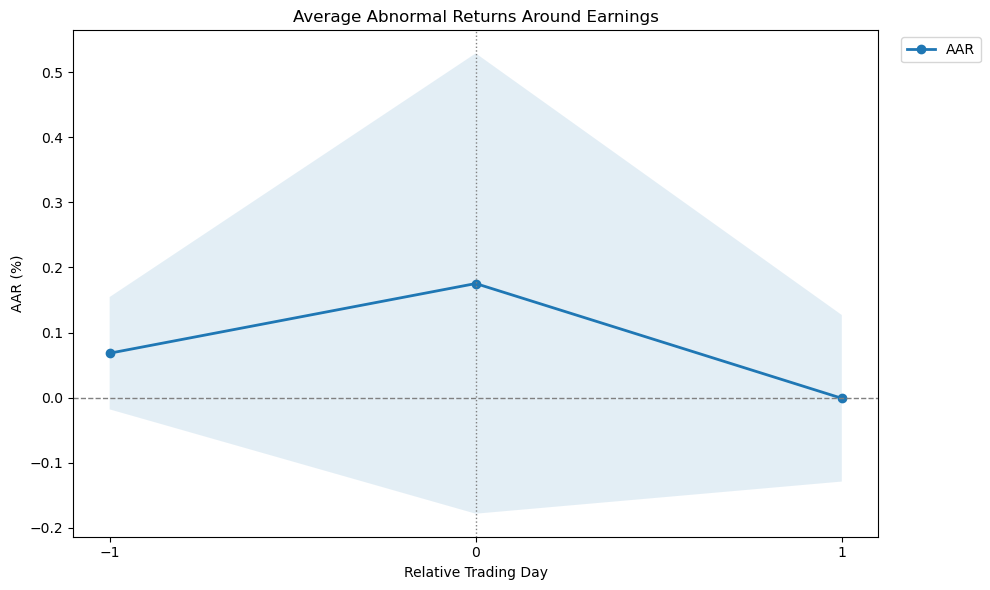

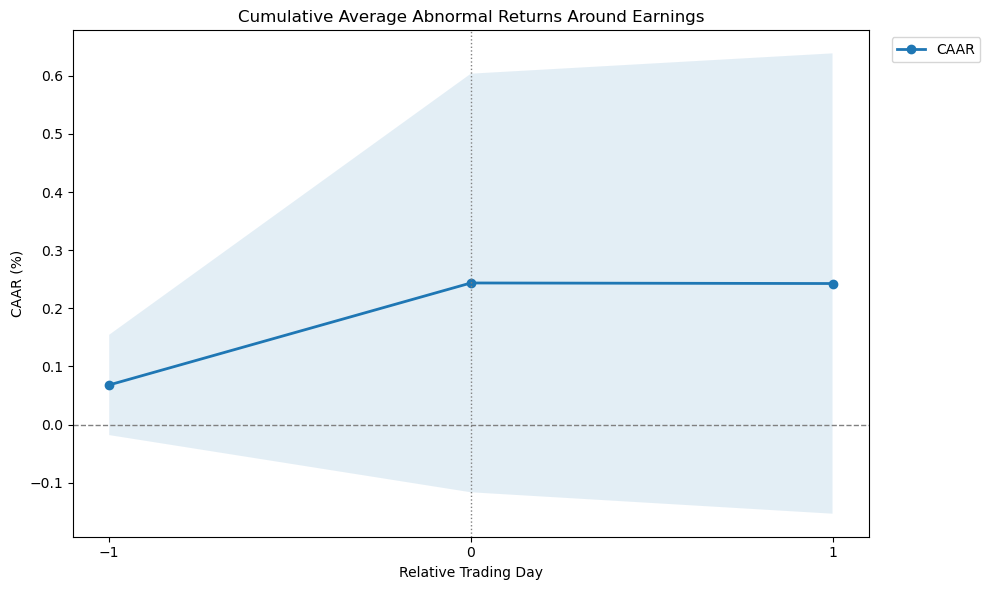

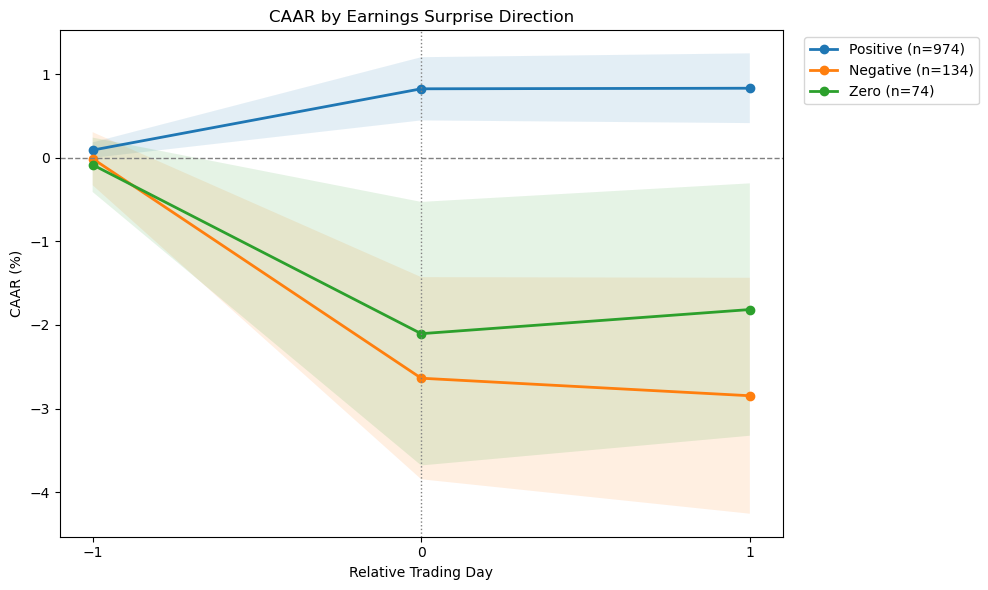

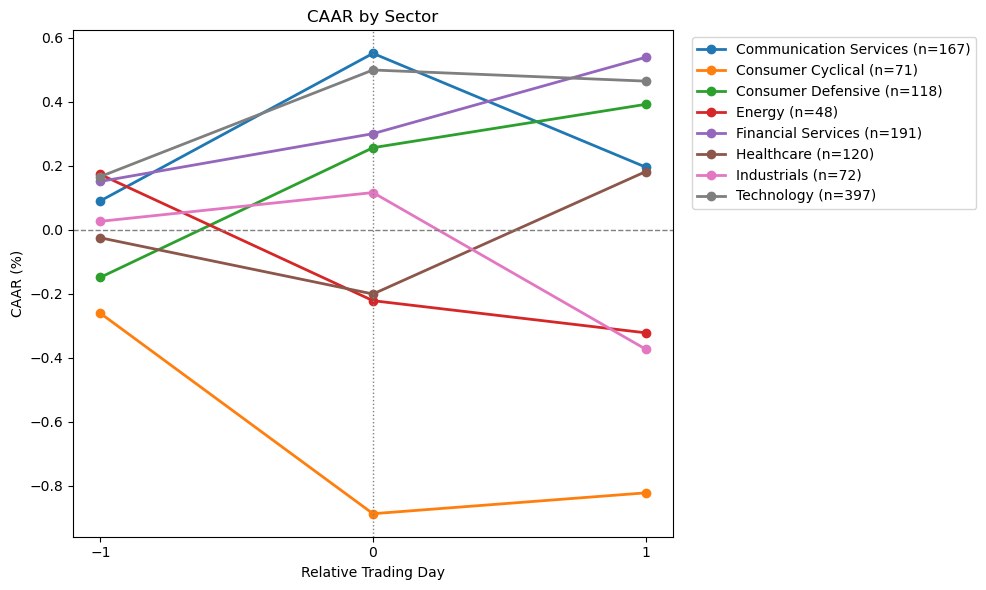

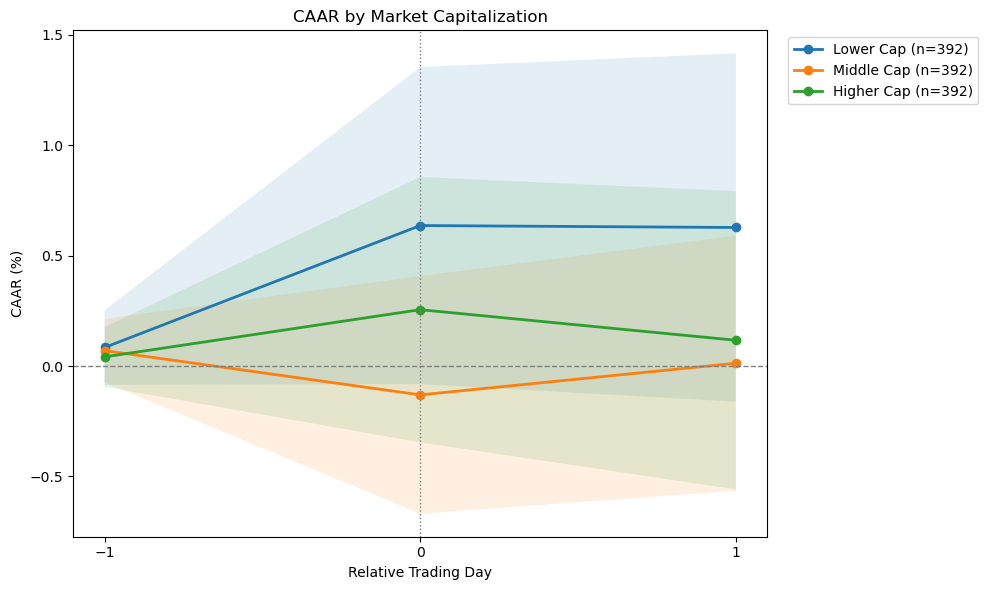

In [92]:
# AAR - all
plot_event_returns(
    aar_test_df,
    title="Average Abnormal Returns Around Earnings",
    metric="aar",
    save_path="../figures/overall_aar.png"
)

# CAAR - all
plot_event_returns(
    caar_daily_test_df,
    title="Cumulative Average Abnormal Returns Around Earnings",
    metric="caar",
    save_path="../figures/overall_caar.png"
)

# Earnings surprise
plot_event_returns(
    surprise_caar,
    title="CAAR by Earnings Surprise Direction",
    group_col="surprise_group",
    groups=["Positive", "Negative", "Zero"],
    save_path="../figures/caar_surprise.png"
)

# Sector
plot_event_returns(
    sector_caar,
    title="CAAR by Sector",
    group_col="sector",
    confidence=False,
    save_path="../figures/caar_sector.png"
)

# Market capitalization
plot_event_returns(
    cap_caar,
    title="CAAR by Market Capitalization",
    group_col="cap_group",
    groups=["Lower Cap", "Middle Cap", "Higher Cap"],
    save_path="../figures/caar_market_cap.png"
)